In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# =============================================================================
# INSTALL REQUIRED PACKAGES
# =============================================================================

!pip -q install lightgbm
!pip -q install shap
!pip -q install lime
!pip -q install imbalanced-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
# =============================================================================
# SECTION 1: IMPORT LIBRARIES & PROJECT SETUP
# =============================================================================

# =========================
# Standard Libraries
# =========================
import os
import random
import warnings
import joblib

warnings.filterwarnings("ignore")

# =========================
# Data Manipulation
# =========================
import numpy as np
import pandas as pd

# =========================
# Data Visualization
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# Machine Learning Utilities
# =========================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# =========================
# Individual ML Models
# =========================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from lightgbm import LGBMClassifier

# =========================
# Hybrid Ensemble Models
# =========================
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import StackingClassifier

# =========================
# Class Imbalance Handling
# =========================
from imblearn.over_sampling import SMOTE

# =========================
# Performance Evaluation
# =========================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# =========================
# Explainable AI
# =========================
import shap
from lime.lime_tabular import LimeTabularExplainer

# =============================================================================
# RANDOM SEED
# =============================================================================

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# =============================================================================
# PROJECT DIRECTORY
# =============================================================================

BASE_DIR = "/content/drive/MyDrive/CKD Research Project"

DATA_PATH = os.path.join(
    BASE_DIR,
    "Dataset",
    "clean_ckd.csv"
)

FIGURE_DIR = os.path.join(
    BASE_DIR,
    "Figures",
    "Notebook_05_Result_Comparison"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "Results",
    "Notebook_05_Result_Comparison"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "Saved_Models",
    "Notebook_05"
)

# Create folders if they do not exist
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# =============================================================================
# PLOT SETTINGS
# =============================================================================

sns.set_style("whitegrid")

plt.rcParams["figure.figsize"] = (8,5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11

# =============================================================================
# INITIALIZATION SUMMARY
# =============================================================================

print("="*80)
print("Notebook 05 Initialized Successfully")
print("="*80)

print(f"\nDataset Path : {DATA_PATH}")
print(f"Figure Folder: {FIGURE_DIR}")
print(f"Result Folder: {RESULT_DIR}")
print(f"Model Folder : {MODEL_DIR}")

print("\nEnvironment Ready for Hybrid Ensemble Learning.")

Notebook 05 Initialized Successfully

Dataset Path : /content/drive/MyDrive/CKD Research Project/Dataset/clean_ckd.csv
Figure Folder: /content/drive/MyDrive/CKD Research Project/Figures/Notebook_05_Result_Comparison
Result Folder: /content/drive/MyDrive/CKD Research Project/Results/Notebook_05_Result_Comparison
Model Folder : /content/drive/MyDrive/CKD Research Project/Saved_Models/Notebook_05

Environment Ready for Hybrid Ensemble Learning.


In [ ]:
# =============================================================================
# SECTION 2: DATASET LOADING & PREPARATION
# =============================================================================

# -------------------------------
# Load Dataset
# -------------------------------

df = pd.read_csv(DATA_PATH)

print("="*80)
print("Dataset Loaded Successfully")
print("="*80)

print(f"\nDataset Shape : {df.shape}")

display(df.head())

# -------------------------------
# Feature & Target Separation
# -------------------------------

X = df.drop("class", axis=1)
y = df["class"]

print("\nFeature Matrix Shape :", X.shape)
print("Target Vector Shape  :", y.shape)

# -------------------------------
# Train-Test Split
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTrain Shape :", X_train.shape)
print("Test Shape  :", X_test.shape)

# -------------------------------
# Feature Scaling
# -------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed Successfully.")

# -------------------------------
# Convert Back to DataFrame
# -------------------------------

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns
)

# -------------------------------
# Dataset Summary
# -------------------------------

dataset_summary = pd.DataFrame({

    "Dataset":[
        "Original Dataset",
        "Training Set",
        "Testing Set"
    ],

    "Samples":[
        len(df),
        len(X_train),
        len(X_test)
    ],

    "Features":[
        X.shape[1],
        X_train.shape[1],
        X_test.shape[1]
    ]

})

display(dataset_summary)

# -------------------------------
# Save Dataset Summary
# -------------------------------

dataset_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "Dataset_Summary.csv"
    ),
    index=False
)

print("\nDataset Summary Saved Successfully.")

Dataset Loaded Successfully

Dataset Shape : (399, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.20000,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.70709,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.70709,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.90000,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.60000,0,0,0,0,0,0,0



Feature Matrix Shape : (399, 24)
Target Vector Shape  : (399,)

Train Shape : (319, 24)
Test Shape  : (80, 24)

Feature Scaling Completed Successfully.


,Dataset,Samples,Features
0,Original Dataset,399,24
1,Training Set,319,24
2,Testing Set,80,24



Dataset Summary Saved Successfully.


CLASS DISTRIBUTION BEFORE SMOTE
Counter({0: 200, 1: 119})


,Class,Count
0,1,119
1,0,200


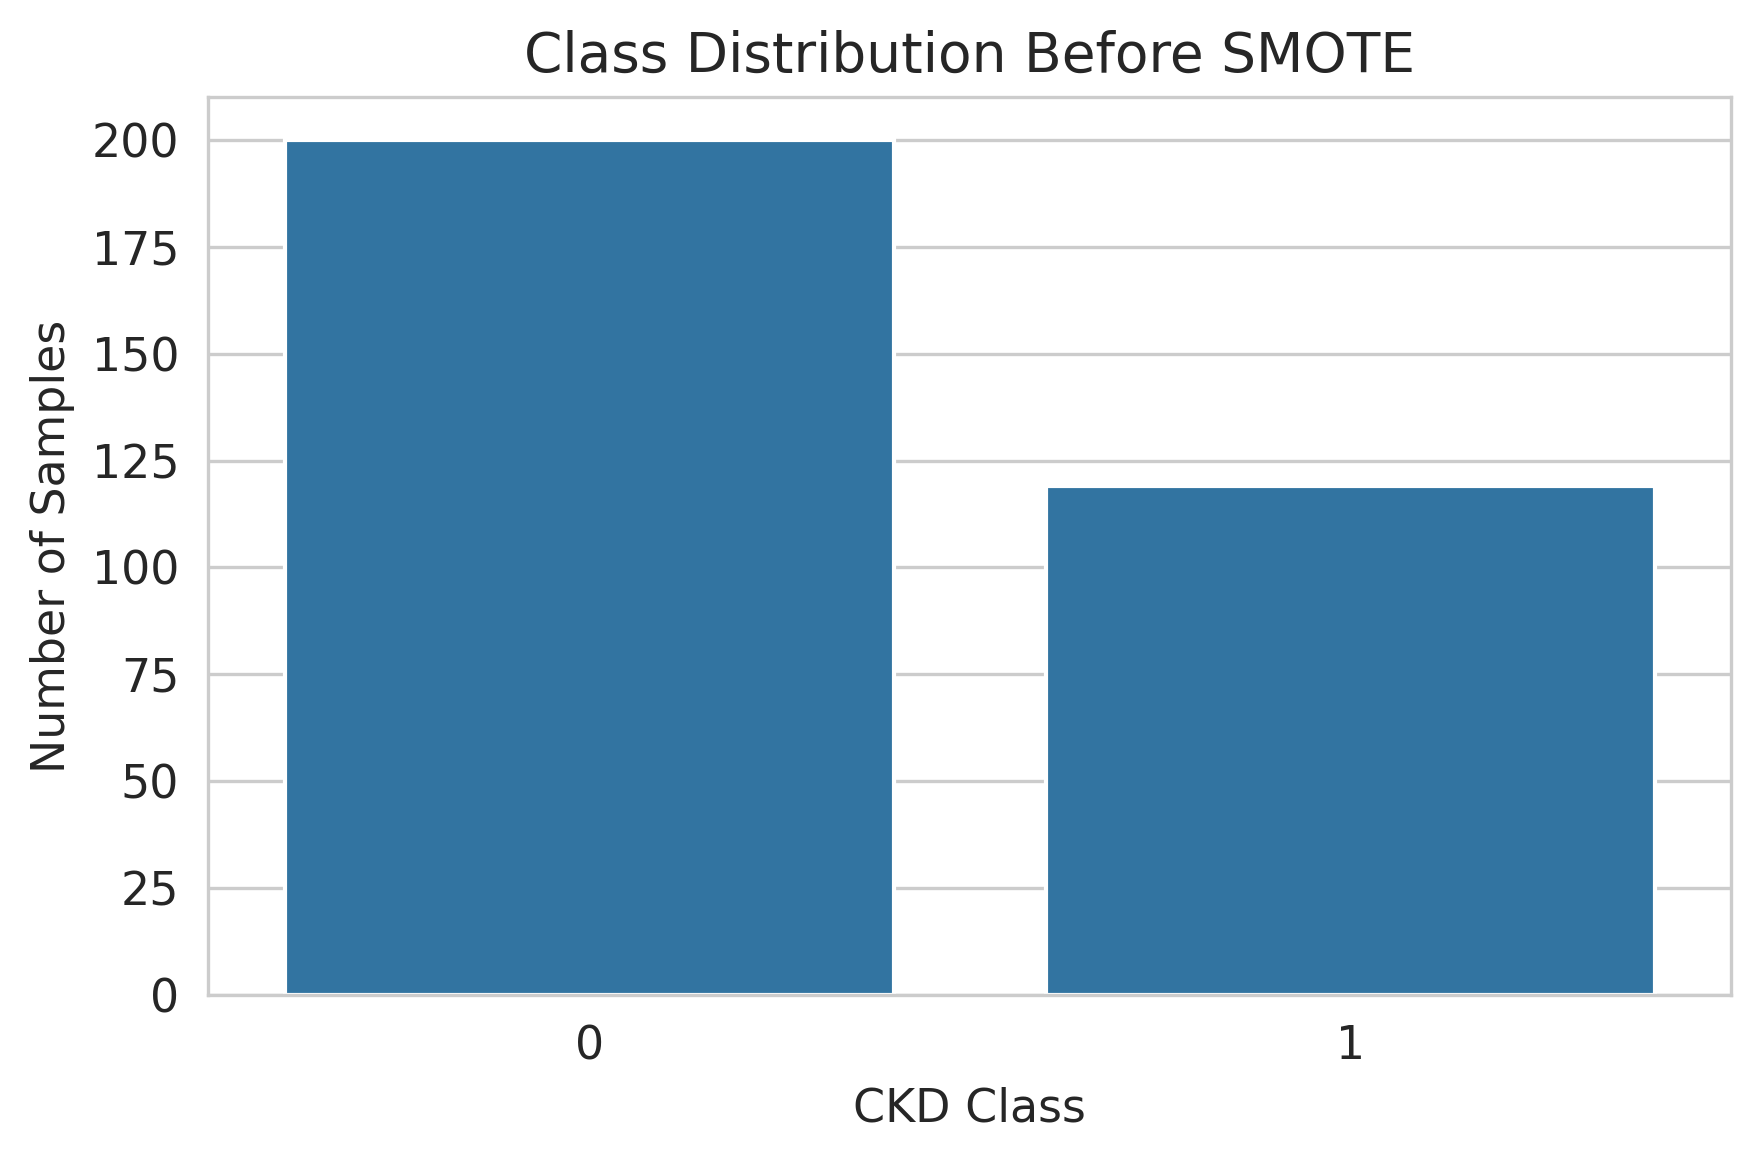


SMOTE Applied Successfully.
CLASS DISTRIBUTION AFTER SMOTE
Counter({1: 200, 0: 200})


,Class,Count
0,1,200
1,0,200


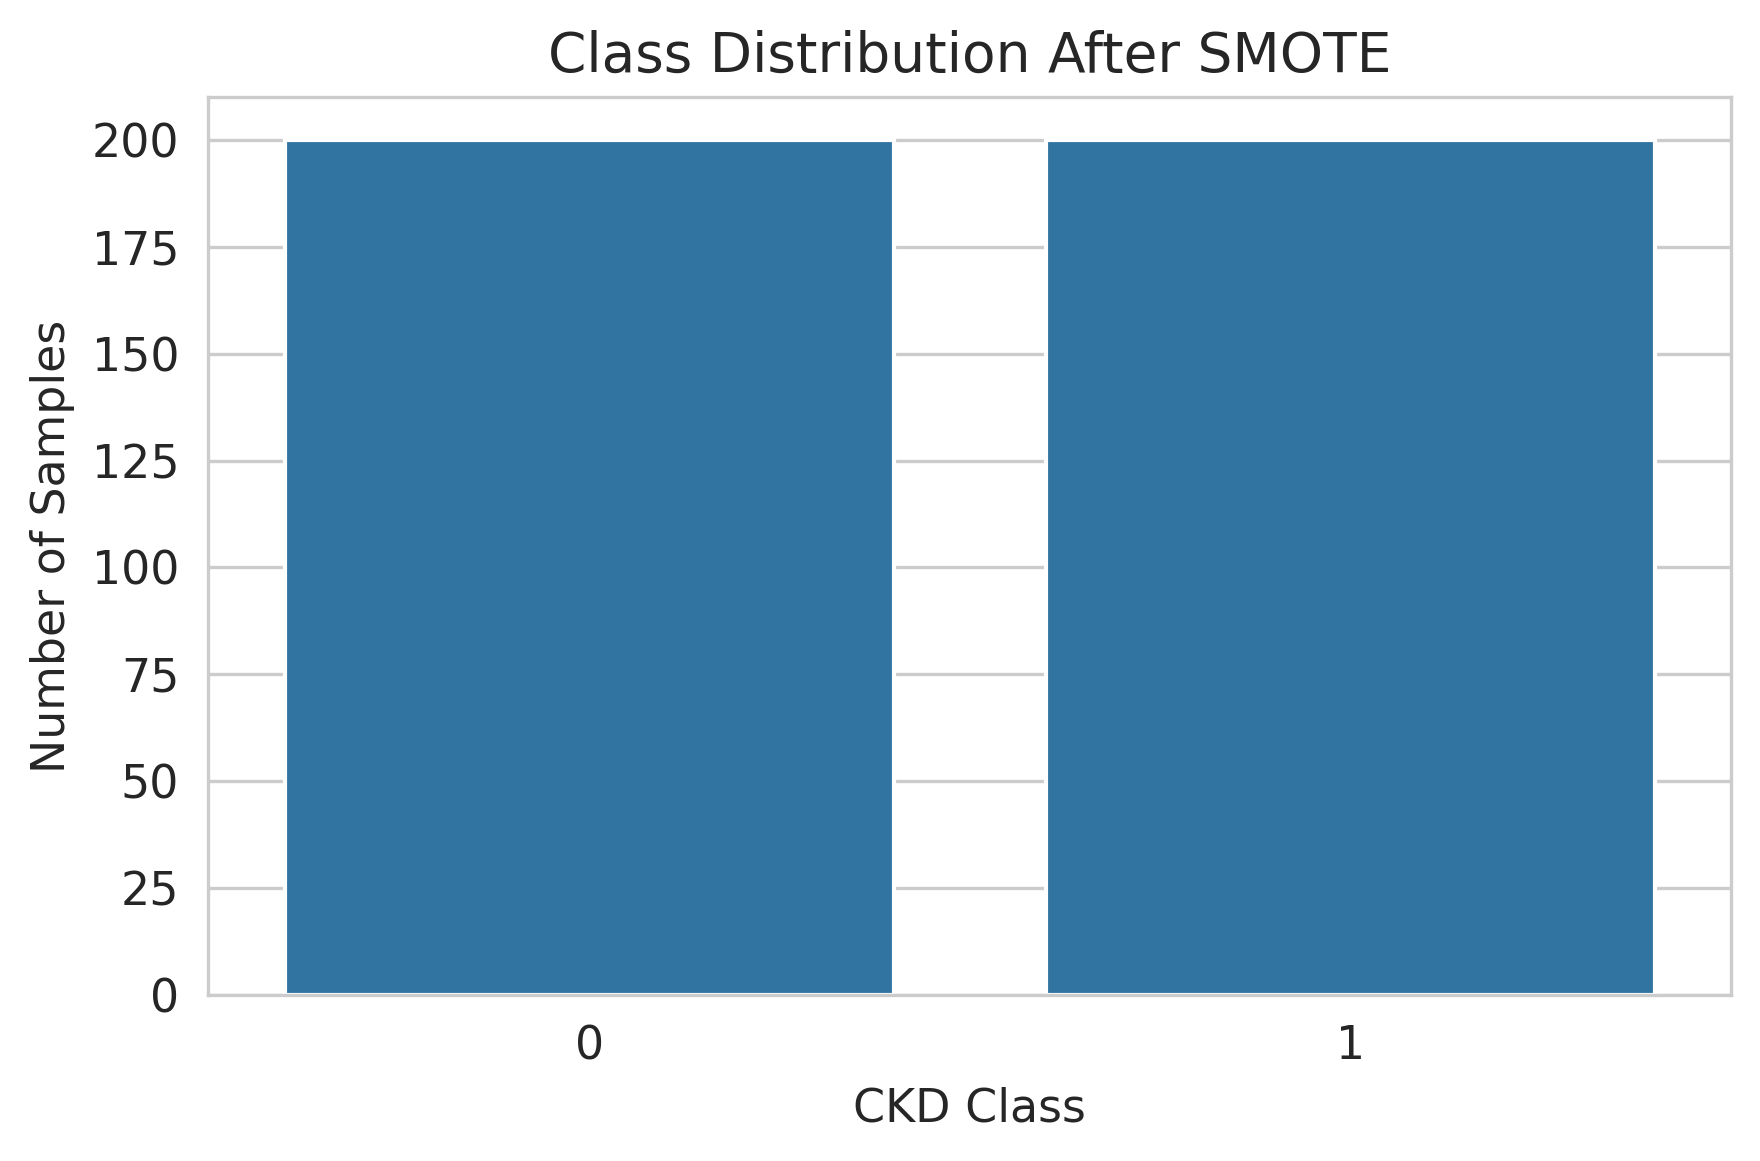


SMOTE Summary Saved Successfully.


In [ ]:
# =============================================================================
# SECTION 3 : SMOTE EXPERIMENT
# =============================================================================

from collections import Counter

# -----------------------------
# Class Distribution (Before)
# -----------------------------

print("="*80)
print("CLASS DISTRIBUTION BEFORE SMOTE")
print("="*80)

before_counts = Counter(y_train)

print(before_counts)

before_df = pd.DataFrame({
    "Class": before_counts.keys(),
    "Count": before_counts.values()
})

display(before_df)

# -----------------------------
# Plot Before SMOTE
# -----------------------------

plt.figure(figsize=(6,4))

sns.countplot(x=y_train)

plt.title("Class Distribution Before SMOTE")
plt.xlabel("CKD Class")
plt.ylabel("Number of Samples")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Class_Distribution_Before_SMOTE.png"
    ),
    dpi=300
)

plt.show()

# -----------------------------
# Apply SMOTE
# -----------------------------

smote = SMOTE(random_state=RANDOM_STATE)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nSMOTE Applied Successfully.")

# -----------------------------
# Class Distribution (After)
# -----------------------------

print("="*80)
print("CLASS DISTRIBUTION AFTER SMOTE")
print("="*80)

after_counts = Counter(y_train_smote)

print(after_counts)

after_df = pd.DataFrame({
    "Class": after_counts.keys(),
    "Count": after_counts.values()
})

display(after_df)

# -----------------------------
# Plot After SMOTE
# -----------------------------

plt.figure(figsize=(6,4))

sns.countplot(x=y_train_smote)

plt.title("Class Distribution After SMOTE")
plt.xlabel("CKD Class")
plt.ylabel("Number of Samples")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Class_Distribution_After_SMOTE.png"
    ),
    dpi=300
)

plt.show()

# -----------------------------
# Save Summary
# -----------------------------

smote_summary = pd.concat(
    [
        before_df.assign(Status="Before_SMOTE"),
        after_df.assign(Status="After_SMOTE")
    ],
    ignore_index=True
)

smote_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "SMOTE_Summary.csv"
    ),
    index=False
)

print("\nSMOTE Summary Saved Successfully.")

In [ ]:
# =============================================================================
# SECTION 4 : HYBRID ENSEMBLE MODEL DEVELOPMENT
# =============================================================================

print("="*80)
print("HYBRID ENSEMBLE MODEL DEVELOPMENT")
print("="*80)

# =============================================================================
# Base Models
# =============================================================================

lr = LogisticRegression(
    random_state=RANDOM_STATE
)

rf = RandomForestClassifier(
    random_state=RANDOM_STATE
)

et = ExtraTreesClassifier(
    random_state=RANDOM_STATE
)

lgbm = LGBMClassifier(
    random_state=RANDOM_STATE,
    verbose=-1
)

# =============================================================================
# Voting Classifier
# =============================================================================

voting_model = VotingClassifier(

    estimators=[

        ("Logistic Regression", lr),
        ("Random Forest", rf),
        ("Extra Trees", et),
        ("LightGBM", lgbm)

    ],

    voting="soft"

)

# =============================================================================
# Stacking Classifier
# =============================================================================

stacking_model = StackingClassifier(

    estimators=[

        ("Logistic Regression", lr),
        ("Random Forest", rf),
        ("Extra Trees", et),
        ("LightGBM", lgbm)

    ],

    final_estimator=LogisticRegression(),

    passthrough=False

)

print("Voting Classifier Created Successfully.")

print("Stacking Classifier Created Successfully.")

HYBRID ENSEMBLE MODEL DEVELOPMENT
Voting Classifier Created Successfully.
Stacking Classifier Created Successfully.


In [ ]:
# =============================================================================
# TRAIN HYBRID MODELS
# =============================================================================

print("="*80)
print("TRAINING HYBRID MODELS")
print("="*80)

# -----------------------------
# Voting Classifier
# -----------------------------

voting_model.fit(
    X_train_smote,
    y_train_smote
)

print("Voting Classifier Training Completed.")

# -----------------------------
# Stacking Classifier
# -----------------------------

stacking_model.fit(
    X_train_smote,
    y_train_smote
)

print("Stacking Classifier Training Completed.")

TRAINING HYBRID MODELS
Voting Classifier Training Completed.
Stacking Classifier Training Completed.


In [ ]:
# =============================================================================
# SAVE HYBRID MODELS
# =============================================================================

joblib.dump(

    voting_model,

    os.path.join(
        MODEL_DIR,
        "Voting_Classifier.pkl"
    )

)

joblib.dump(

    stacking_model,

    os.path.join(
        MODEL_DIR,
        "Stacking_Classifier.pkl"
    )

)

print("="*80)
print("Hybrid Models Saved Successfully")
print("="*80)

Hybrid Models Saved Successfully


In [ ]:
# =============================================================================
# SECTION 5 : HYBRID MODEL EVALUATION
# =============================================================================

def evaluate_model(model, model_name):

    # Prediction
    y_pred = model.predict(X_test_scaled)

    # Probability
    y_prob = model.predict_proba(X_test_scaled)[:,1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test, y_pred)

    recall = recall_score(y_test, y_pred)

    f1 = f1_score(y_test, y_pred)

    roc_auc = roc_auc_score(y_test, y_prob)

    return {

        "Model":model_name,

        "Accuracy":accuracy,

        "Precision":precision,

        "Recall":recall,

        "F1":f1,

        "ROC_AUC":roc_auc

    }

In [ ]:
# =============================================================================
# Evaluate Voting & Stacking
# =============================================================================

results=[]

results.append(
    evaluate_model(
        voting_model,
        "Voting Classifier"
    )
)

results.append(
    evaluate_model(
        stacking_model,
        "Stacking Classifier"
    )
)

hybrid_results=pd.DataFrame(results)

display(hybrid_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Voting Classifier,1.0,1.0,1.0,1.0,1.0
1,Stacking Classifier,1.0,1.0,1.0,1.0,1.0


In [ ]:
# =============================================================================
# Save Results
# =============================================================================

hybrid_results.to_csv(

    os.path.join(

        RESULT_DIR,

        "Hybrid_Model_Performance.csv"

    ),

    index=False

)

print("="*80)
print("Hybrid Model Performance Saved Successfully")
print("="*80)

Hybrid Model Performance Saved Successfully


In [ ]:
# =============================================================================
# Best Hybrid Model
# =============================================================================

best_hybrid=hybrid_results.sort_values(

    by="Accuracy",

    ascending=False

).iloc[0]

print("="*80)
print("BEST HYBRID MODEL")
print("="*80)

display(best_hybrid)

BEST HYBRID MODEL


,0
Model,Voting Classifier
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
ROC_AUC,1.0


In [ ]:
# =============================================================================
# LOAD NOTEBOOK 03 RESULTS
# =============================================================================

ml_results = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "Results",
        "model_comparison.csv"
    )
)

print("="*80)
print("Machine Learning Results Loaded Successfully")
print("="*80)

display(ml_results.head())

Machine Learning Results Loaded Successfully


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,SVC,1.0000,1.0000,1.0000,1.0000,1.0000
1,LogisticRegression,0.9875,0.9677,1.0000,0.9836,0.9993
2,KNeighborsClassifier,0.9875,0.9677,1.0000,0.9836,0.9890
3,ExtraTreesClassifier,0.9875,1.0000,0.9667,0.9831,1.0000
4,RandomForestClassifier,0.9750,1.0000,0.9333,0.9655,0.9993


In [ ]:
# =============================================================================
# SELECT BEST INDIVIDUAL MODELS
# =============================================================================

selected_models = [

    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "LightGBM"

]

ml_results = ml_results[
    ml_results["Model"].isin(selected_models)
]

display(ml_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC


In [16]:
# =============================================================================
# MERGE ML & HYBRID RESULTS
# =============================================================================

final_results = pd.concat(

    [

        ml_results,

        hybrid_results

    ],

    ignore_index=True

)

display(final_results)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Voting Classifier,1.0,1.0,1.0,1.0,1.0
1,Stacking Classifier,1.0,1.0,1.0,1.0,1.0


In [17]:
# =============================================================================
# MODEL RANKING
# =============================================================================

final_results = final_results.sort_values(

    by="Accuracy",

    ascending=False

)

final_results.reset_index(

    drop=True,

    inplace=True

)

final_results.insert(

    0,

    "Rank",

    range(1,len(final_results)+1)

)

display(final_results)

,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,Voting Classifier,1.0,1.0,1.0,1.0,1.0
1,2,Stacking Classifier,1.0,1.0,1.0,1.0,1.0


In [18]:
# =============================================================================
# SAVE FINAL COMPARISON
# =============================================================================

final_results.to_csv(

    os.path.join(

        RESULT_DIR,

        "Final_Model_Comparison.csv"

    ),

    index=False

)

print("="*80)
print("Final Comparison Saved Successfully")
print("="*80)

Final Comparison Saved Successfully


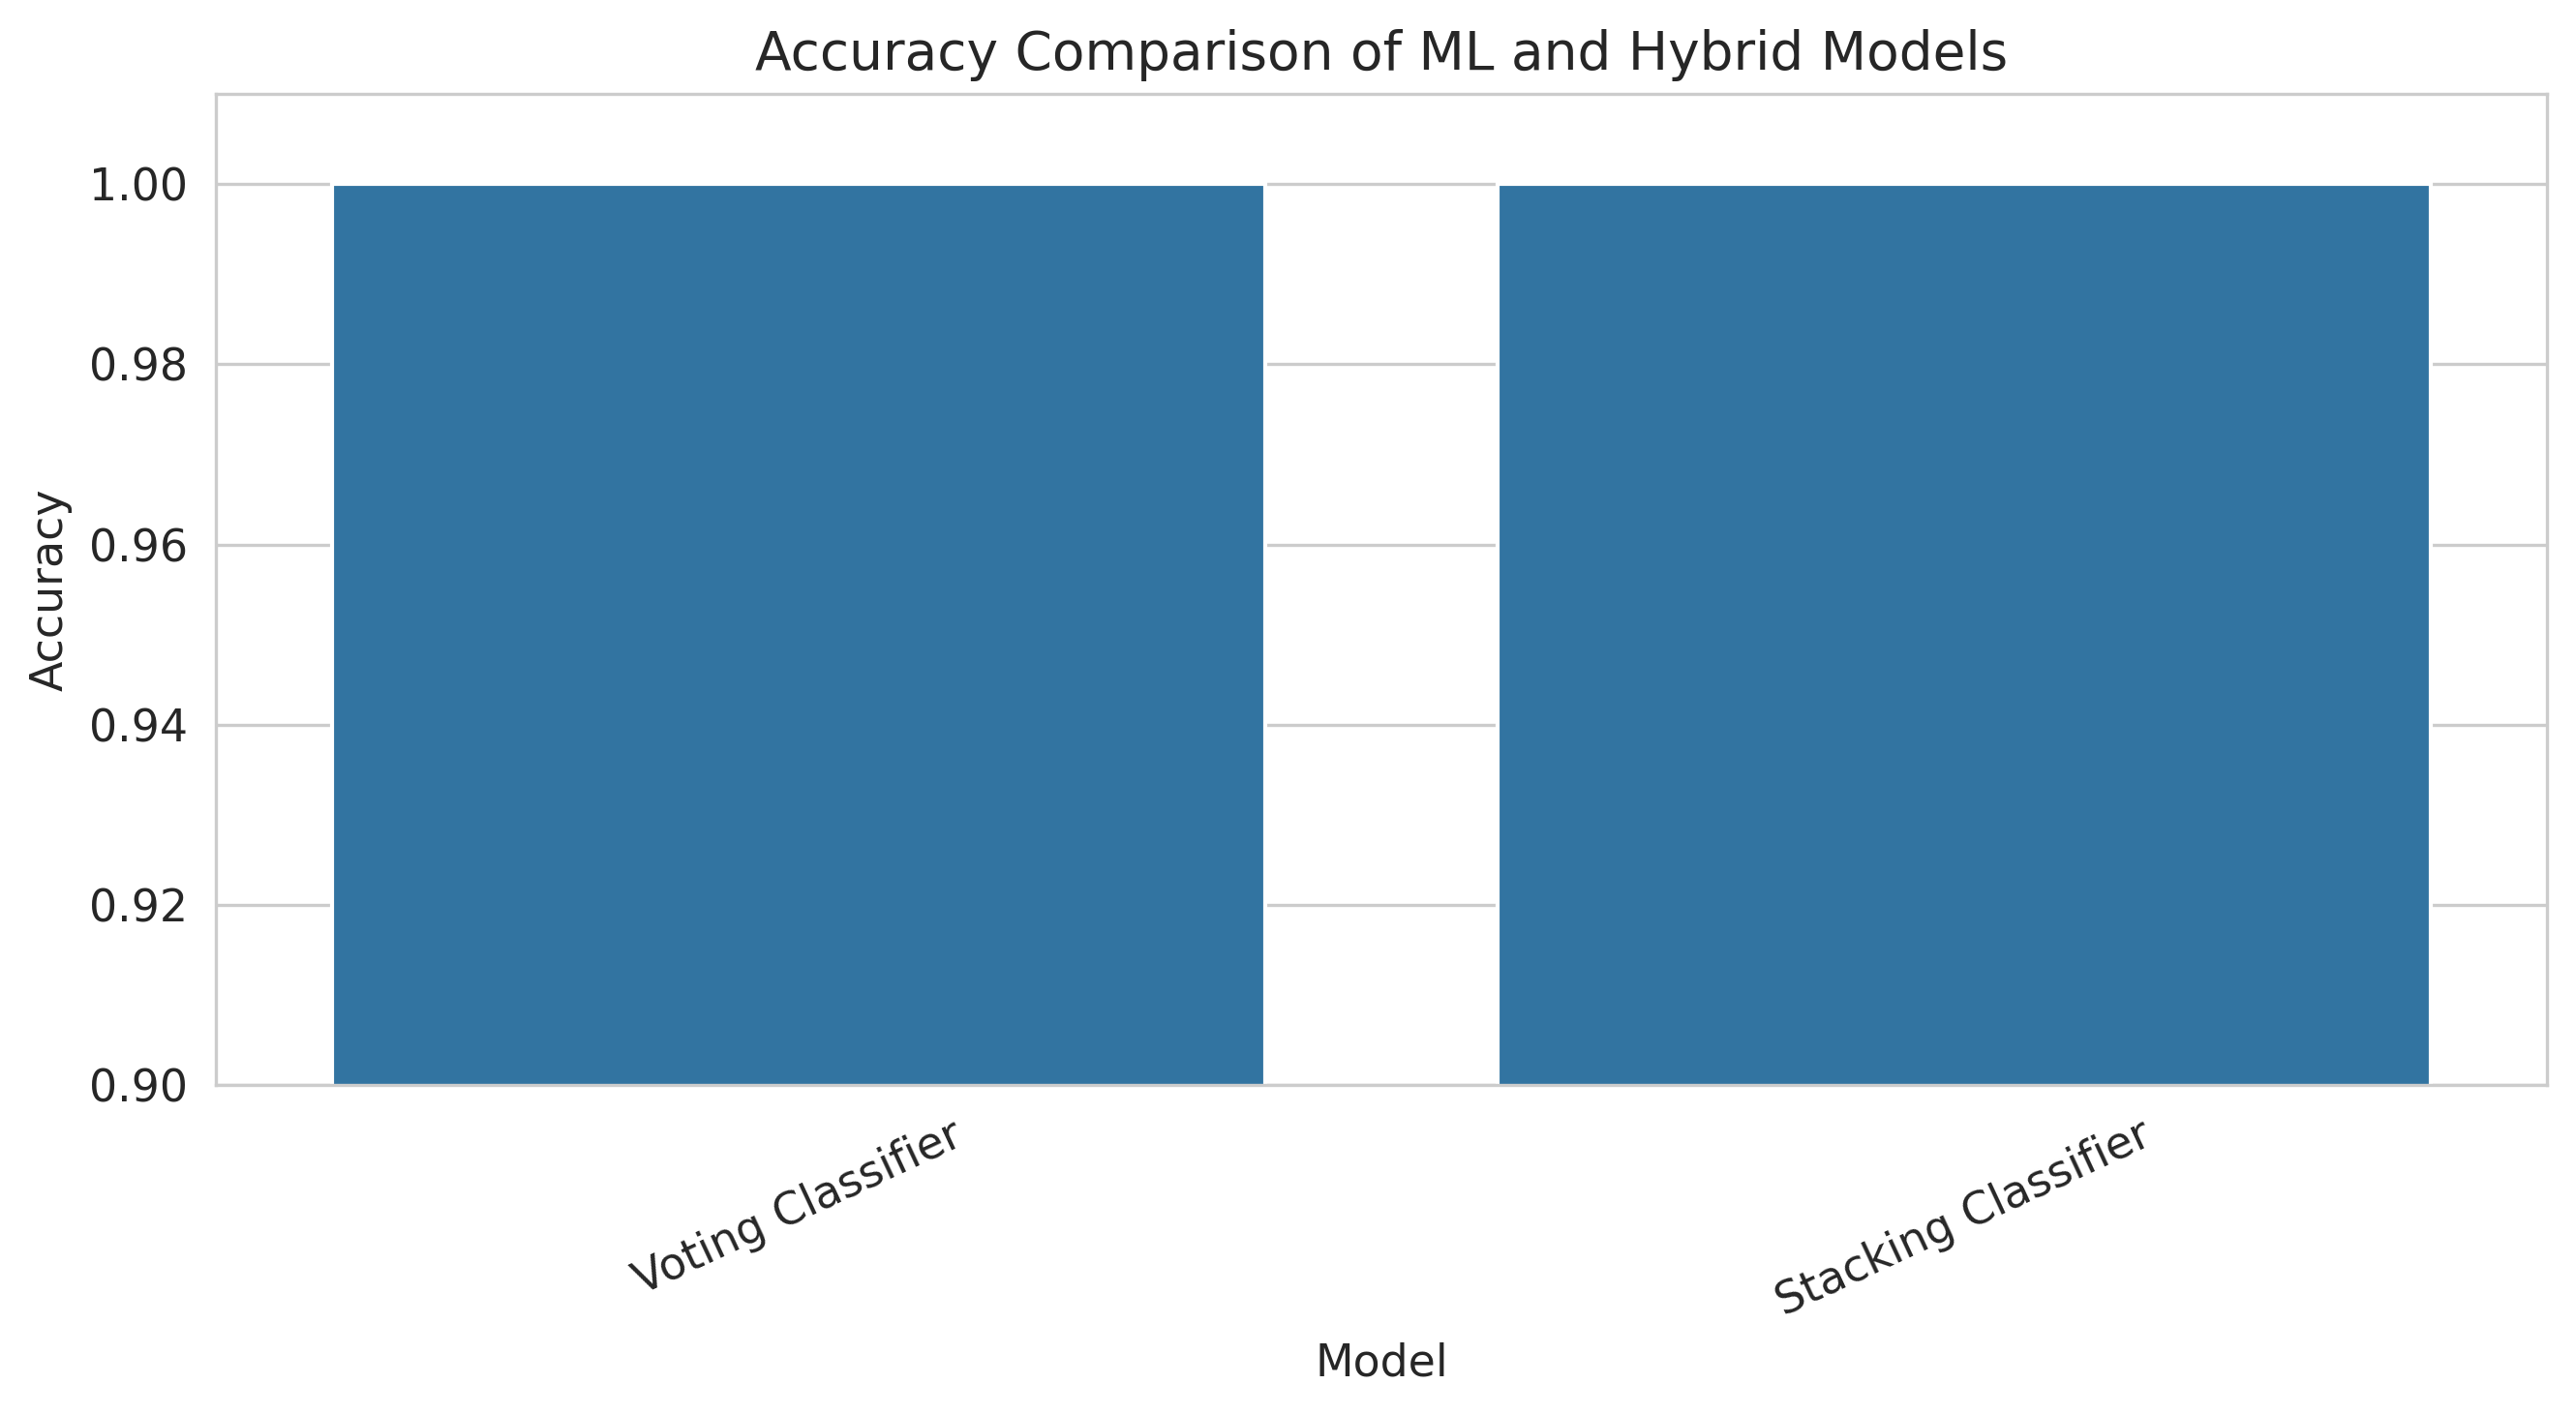

In [19]:
# =============================================================================
# ACCURACY COMPARISON
# =============================================================================

plt.figure(figsize=(9,5))

sns.barplot(

    data=final_results,

    x="Model",

    y="Accuracy"

)

plt.xticks(rotation=25)

plt.ylim(0.90,1.01)

plt.title("Accuracy Comparison of ML and Hybrid Models")

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "Accuracy_Comparison.png"

    ),

    dpi=300

)

plt.show()

In [20]:
# =============================================================================
# OVERFITTING ANALYSIS
# =============================================================================

train_scores=[]

test_scores=[]

models={

    "Voting":voting_model,

    "Stacking":stacking_model

}

for name,model in models.items():

    train_acc=accuracy_score(

        y_train_smote,

        model.predict(X_train_smote)

    )

    test_acc=accuracy_score(

        y_test,

        model.predict(X_test_scaled)

    )

    train_scores.append(train_acc)

    test_scores.append(test_acc)

overfitting_df=pd.DataFrame({

    "Model":list(models.keys()),

    "Train Accuracy":train_scores,

    "Test Accuracy":test_scores

})

overfitting_df["Gap"]=overfitting_df["Train Accuracy"]-overfitting_df["Test Accuracy"]

display(overfitting_df)

,Model,Train Accuracy,Test Accuracy,Gap
0,Voting,1.0,1.0,0.0
1,Stacking,1.0,1.0,0.0


In [21]:
# =============================================================================
# SAVE OVERFITTING ANALYSIS
# =============================================================================

overfitting_df.to_csv(

    os.path.join(

        RESULT_DIR,

        "Hybrid_Overfitting_Analysis.csv"

    ),

    index=False

)

print("Overfitting Analysis Saved Successfully.")

Overfitting Analysis Saved Successfully.


In [22]:
# =============================================================================
# Section 7: SHAP Explainability Analysis
# =============================================================================

# =============================================================================
# SECTION 7 : SELECT BEST HYBRID MODEL
# =============================================================================

if hybrid_results.loc[0, "Accuracy"] >= hybrid_results.loc[1, "Accuracy"]:

    best_model = voting_model
    best_model_name = "Voting Classifier"

else:

    best_model = stacking_model
    best_model_name = "Stacking Classifier"

print("="*80)
print("Best Hybrid Model")
print("="*80)

print(best_model_name)

Best Hybrid Model
Voting Classifier


In [23]:
# =============================================================================
# CREATE SHAP EXPLAINER
# =============================================================================

explainer = shap.Explainer(
    best_model.predict,
    X_train_smote
)

print("SHAP Explainer Created Successfully.")

SHAP Explainer Created Successfully.


In [24]:
# =============================================================================
# COMPUTE SHAP VALUES
# =============================================================================

shap_values = explainer(X_test_scaled)

print("SHAP Values Generated Successfully.")

PermutationExplainer explainer: 81it [01:05,  1.22it/s]

SHAP Values Generated Successfully.


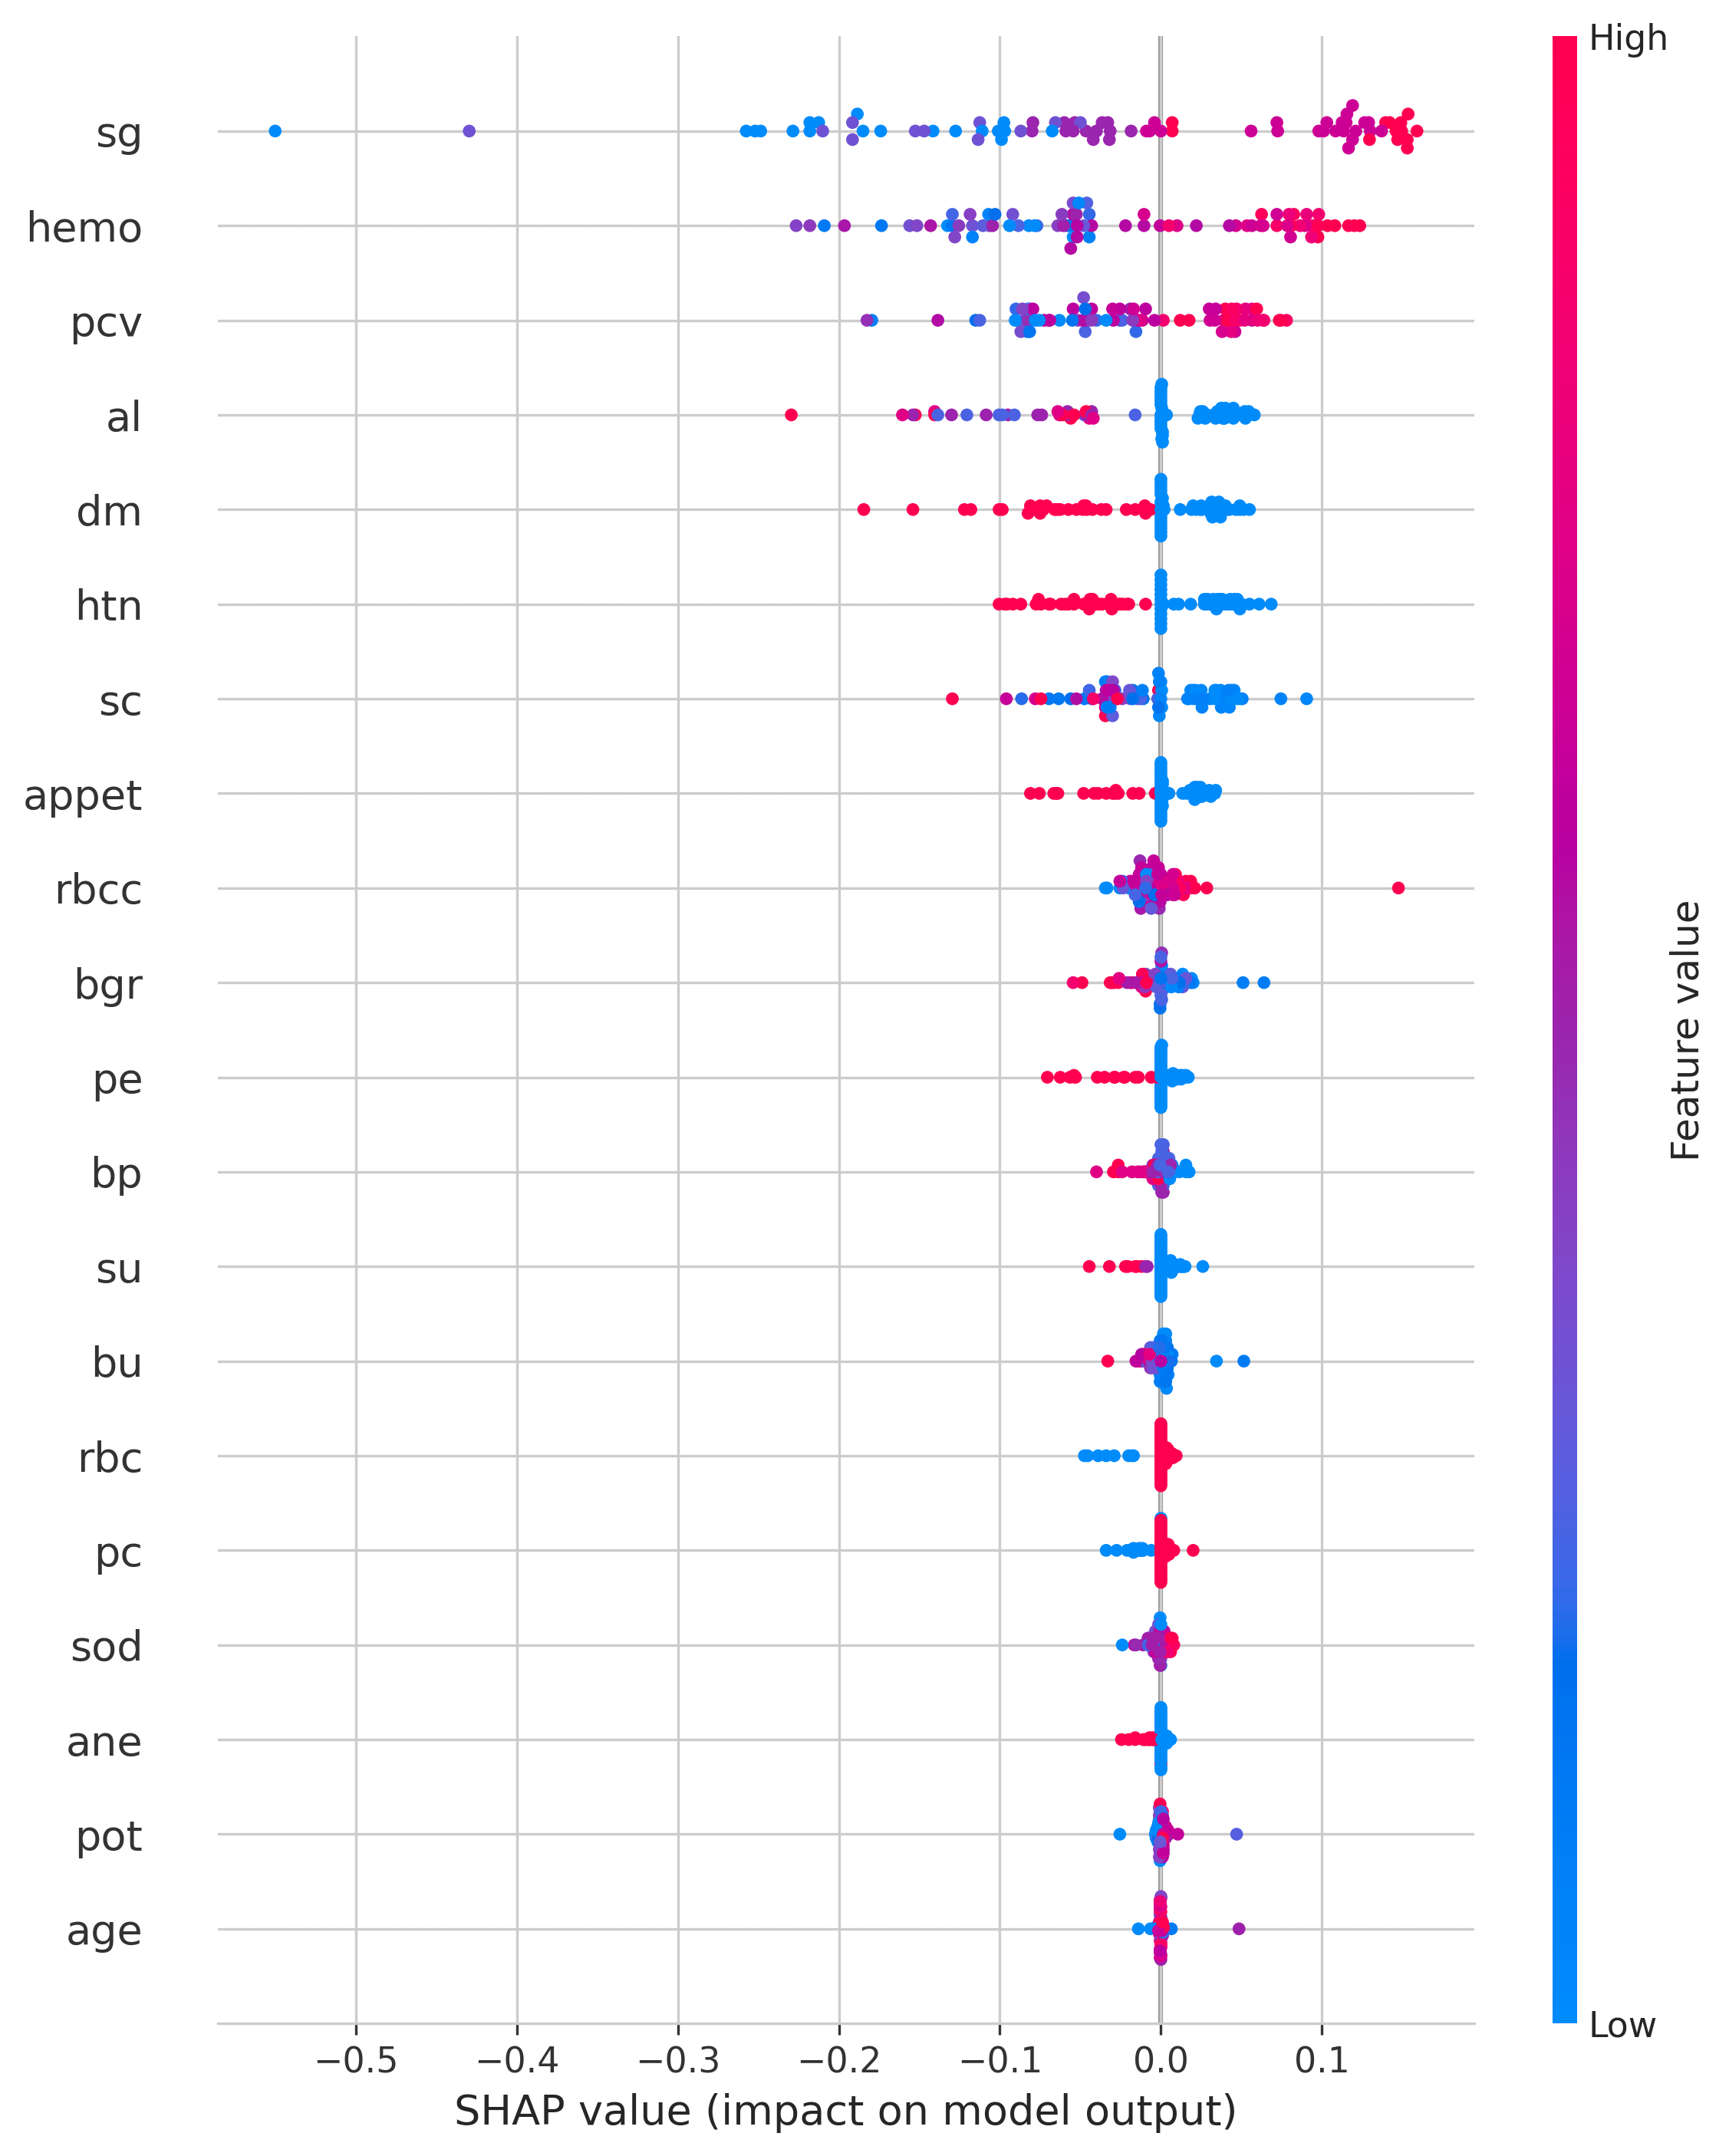

In [25]:
# =============================================================================
# SHAP SUMMARY PLOT
# =============================================================================

plt.figure(figsize=(8,6))

shap.summary_plot(

    shap_values,

    X_test_scaled,

    show=False

)

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "SHAP_Summary_Plot.png"

    ),

    dpi=300,

    bbox_inches="tight"

)

plt.show()

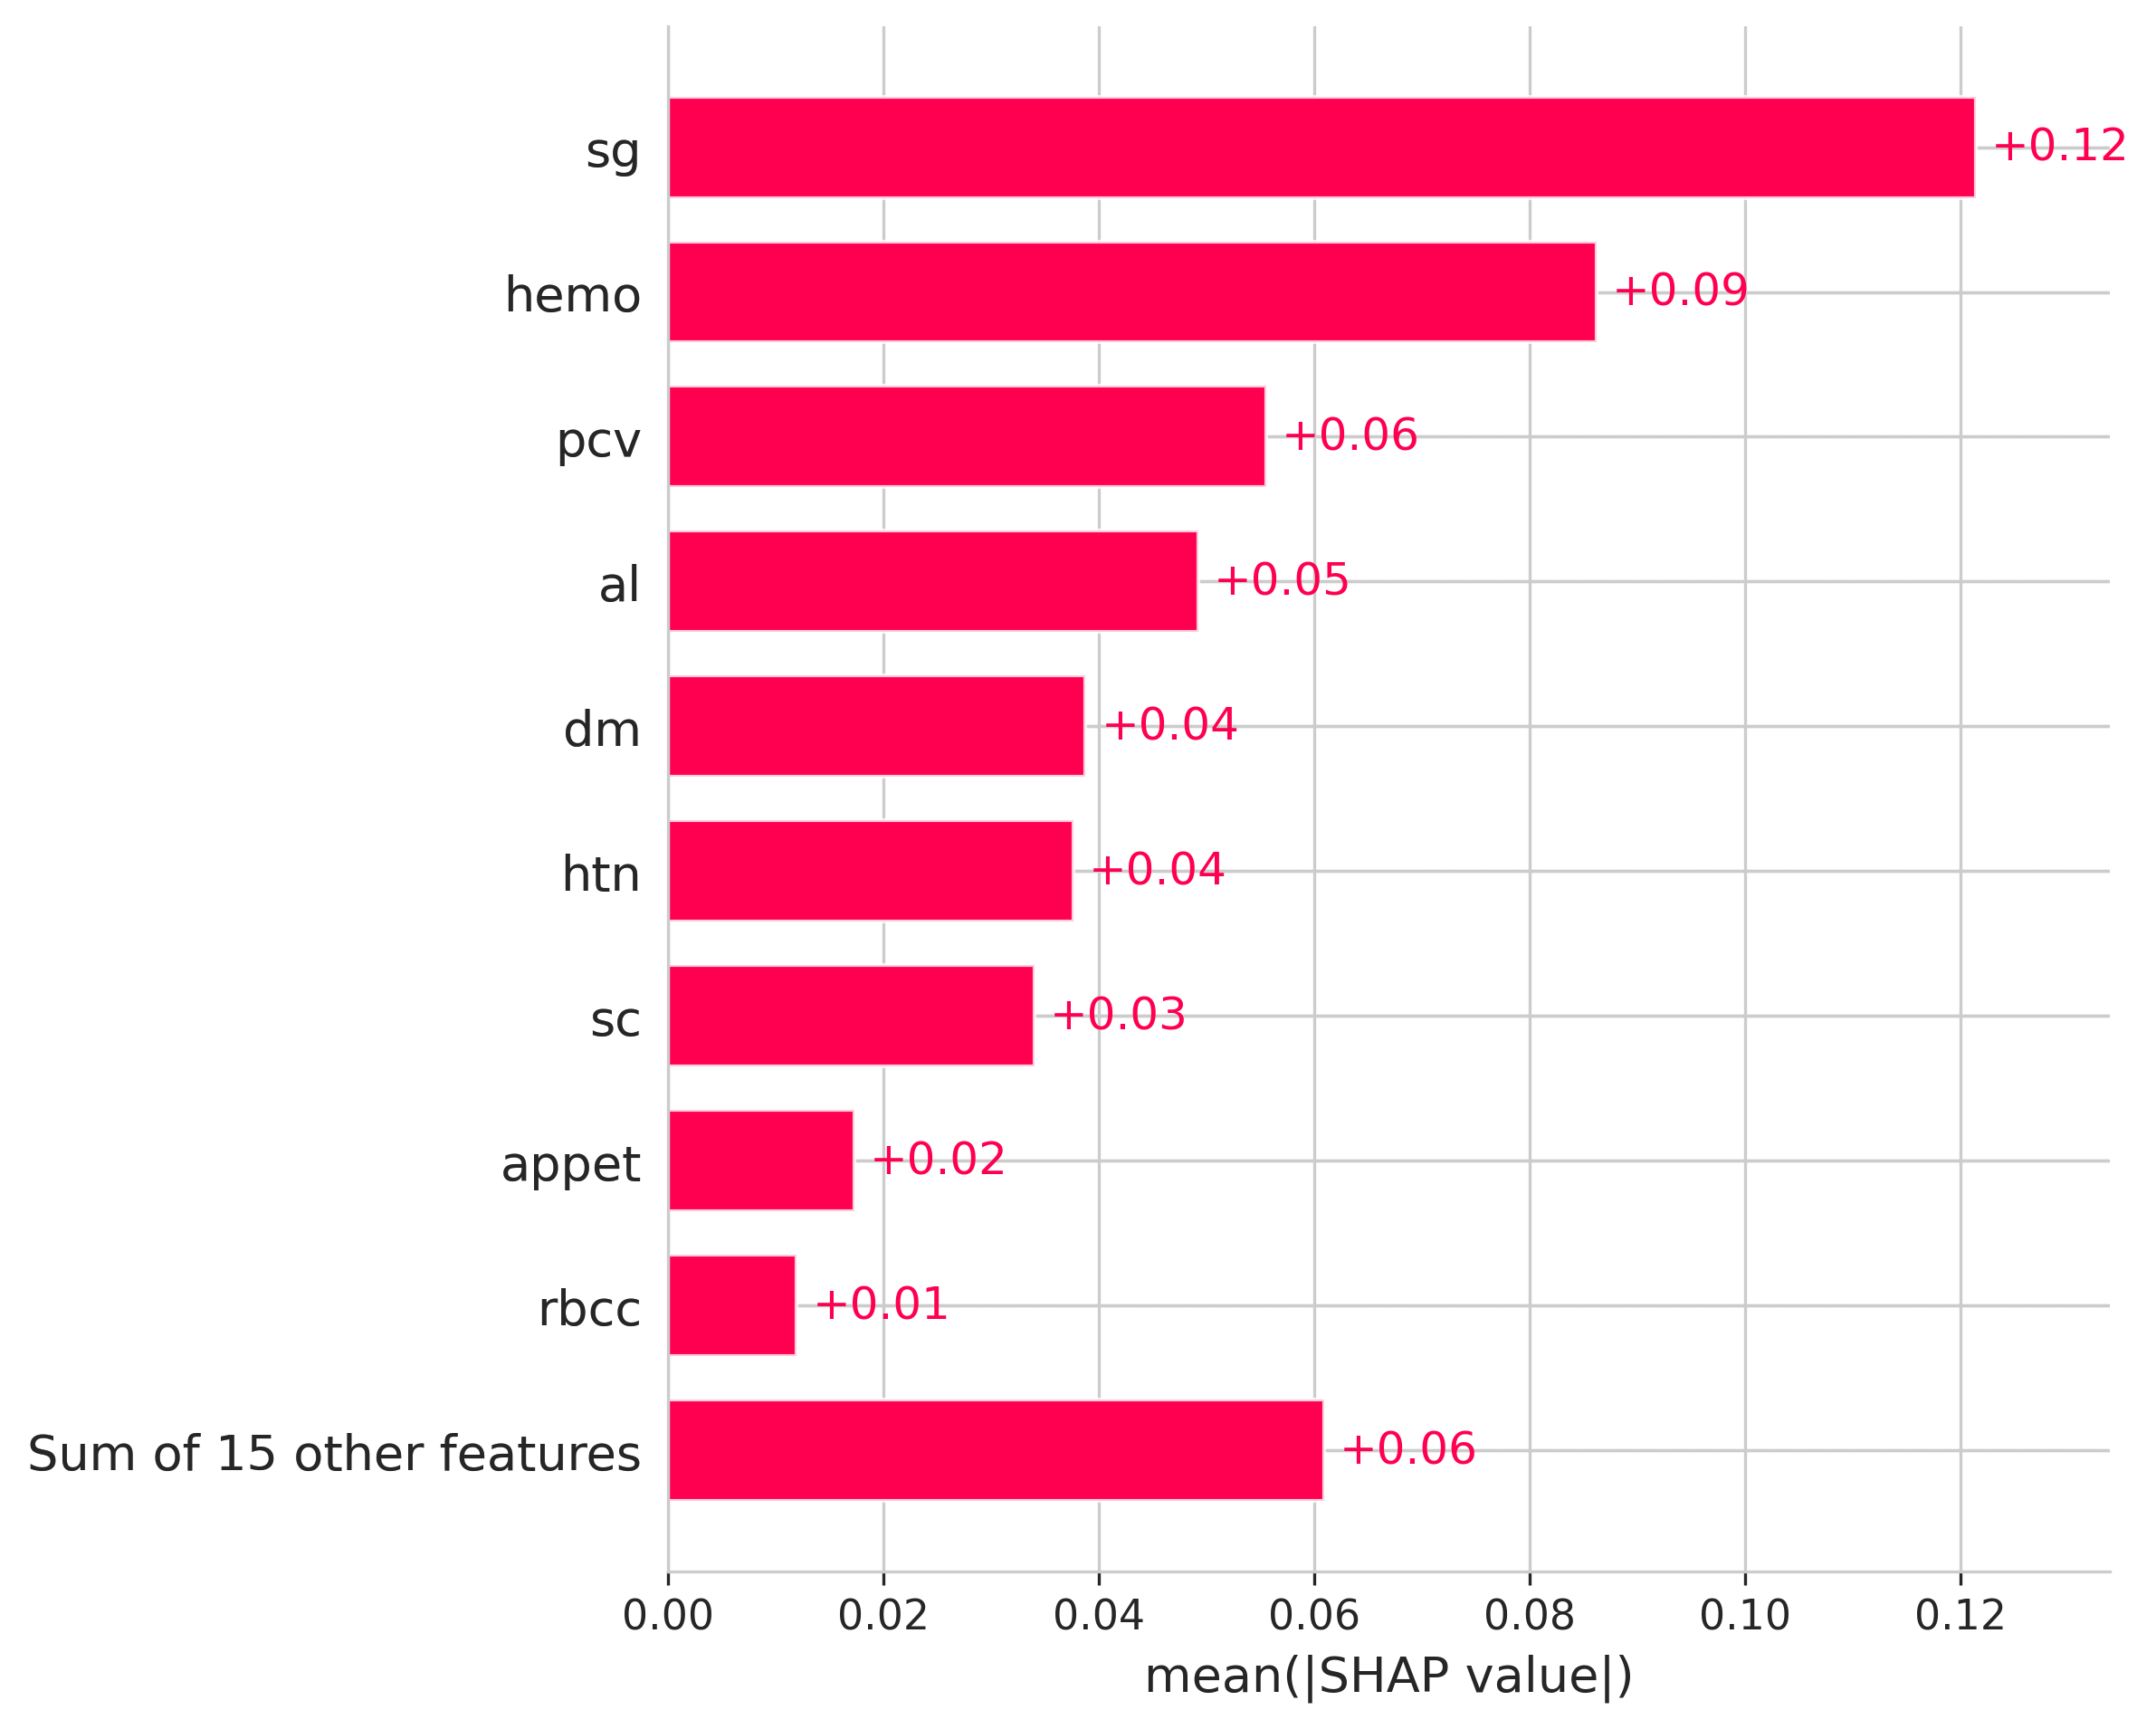

In [26]:
# =============================================================================
# SHAP BAR PLOT
# =============================================================================

plt.figure(figsize=(8,6))

shap.plots.bar(

    shap_values,

    show=False

)

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "SHAP_Feature_Importance.png"

    ),

    dpi=300,

    bbox_inches="tight"

)

plt.show()

In [27]:
# =============================================================================
# GLOBAL FEATURE IMPORTANCE
# =============================================================================

importance = np.abs(shap_values.values).mean(axis=0)

feature_importance = pd.DataFrame({

    "Feature":X.columns,

    "Mean_SHAP_Value":importance

})

feature_importance = feature_importance.sort_values(

    by="Mean_SHAP_Value",

    ascending=False

)

display(feature_importance.head(15))

,Feature,Mean_SHAP_Value
2,sg,0.121400
14,hemo,0.086194
15,pcv,0.055550
3,al,0.049219
19,dm,0.038750
18,htn,0.037638
11,sc,0.034013
21,appet,0.017287
17,rbcc,0.011950
9,bgr,0.010862


In [28]:
# =============================================================================
# SAVE FEATURE IMPORTANCE
# =============================================================================

feature_importance.to_csv(

    os.path.join(

        RESULT_DIR,

        "SHAP_Feature_Importance.csv"

    ),

    index=False

)

print("="*80)
print("SHAP Feature Importance Saved Successfully")
print("="*80)

SHAP Feature Importance Saved Successfully


In [29]:
# =============================================================================
# Section 8: LIME Explainability Analysis
# =============================================================================
# =============================================================================
# SECTION 8 : CREATE LIME EXPLAINER
# =============================================================================

lime_explainer = LimeTabularExplainer(

    training_data=np.array(X_train_smote),

    feature_names=X.columns.tolist(),

    class_names=["CKD","Not CKD"],

    mode="classification",

    random_state=RANDOM_STATE

)

print("="*80)
print("LIME Explainer Created Successfully")
print("="*80)

LIME Explainer Created Successfully


In [30]:
# =============================================================================
# SELECT SAMPLE
# =============================================================================

sample_index = 0

sample = X_test_scaled.iloc[sample_index]

print("Selected Test Sample :", sample_index)

Selected Test Sample : 0


In [31]:
# =============================================================================
# GENERATE LIME EXPLANATION
# =============================================================================

lime_exp = lime_explainer.explain_instance(

    data_row=sample,

    predict_fn=best_model.predict_proba,

    num_features=10

)

print("LIME Explanation Generated Successfully.")

LIME Explanation Generated Successfully.


In [32]:
# =============================================================================
# DISPLAY LIME EXPLANATION
# =============================================================================

lime_exp.show_in_notebook(show_table=True)

In [33]:
# =============================================================================
# SAVE LIME EXPLANATION
# =============================================================================

lime_exp.save_to_file(

    os.path.join(

        FIGURE_DIR,

        "LIME_Explanation.html"

    )

)

print("="*80)
print("LIME Explanation Saved Successfully")
print("="*80)

LIME Explanation Saved Successfully


In [34]:
# =============================================================================
# SECTION 9 : FEATURE IMPORTANCE RANKING
# =============================================================================

# Calculate Mean Absolute SHAP Value

importance = np.abs(shap_values.values).mean(axis=0)

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": importance

})

feature_importance = feature_importance.sort_values(

    by="Importance",

    ascending=False

)

feature_importance.reset_index(

    drop=True,

    inplace=True

)

display(feature_importance.head(15))

,Feature,Importance
0,sg,0.121400
1,hemo,0.086194
2,pcv,0.055550
3,al,0.049219
4,dm,0.038750
5,htn,0.037638
6,sc,0.034013
7,appet,0.017287
8,rbcc,0.011950
9,bgr,0.010862


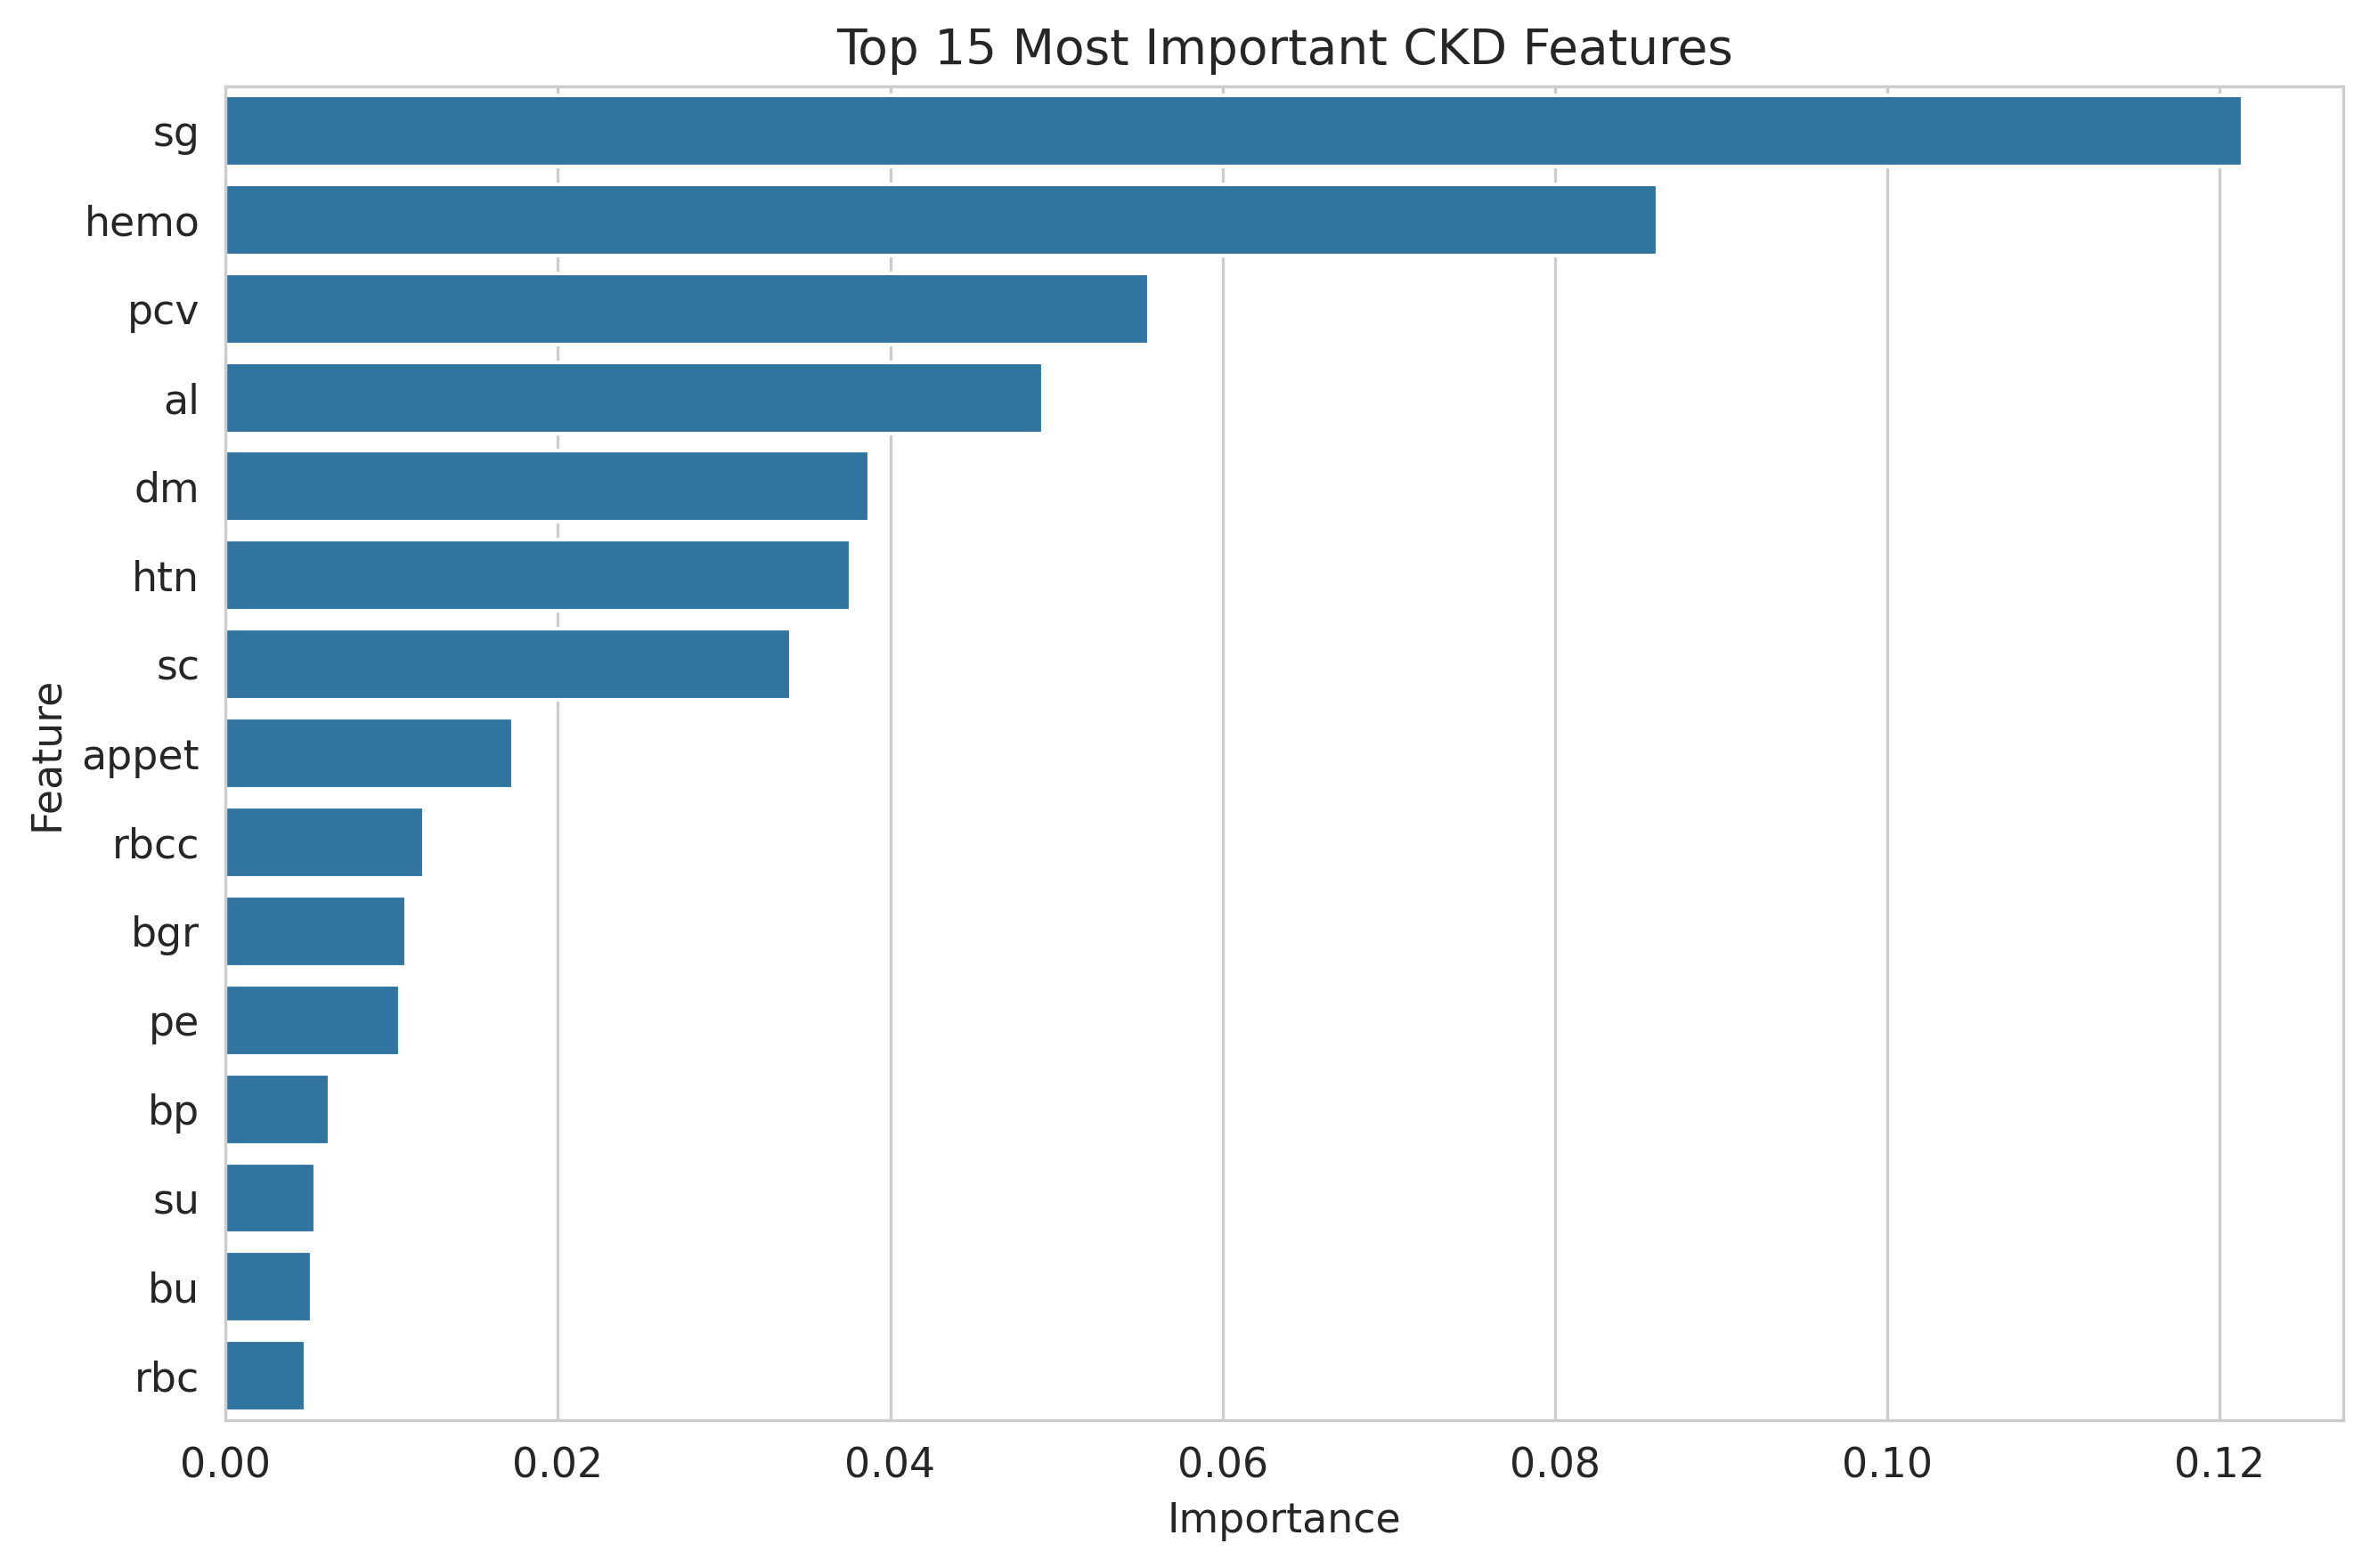

In [35]:
# =============================================================================
# TOP 15 FEATURE VISUALIZATION
# =============================================================================

top15 = feature_importance.head(15)

plt.figure(figsize=(9,6))

sns.barplot(

    data=top15,

    y="Feature",

    x="Importance"

)

plt.title("Top 15 Most Important CKD Features")

plt.tight_layout()

plt.savefig(

    os.path.join(

        FIGURE_DIR,

        "Top15_SHAP_Features.png"

    ),

    dpi=300

)

plt.show()

In [36]:
# =============================================================================
# SAVE FEATURE IMPORTANCE
# =============================================================================

feature_importance.to_csv(

    os.path.join(

        RESULT_DIR,

        "Feature_Importance_Ranking.csv"

    ),

    index=False

)

print("="*80)
print("Feature Importance Ranking Saved Successfully")
print("="*80)

Feature Importance Ranking Saved Successfully


In [37]:
# =============================================================================
# TOP 10 FEATURES
# =============================================================================

top10 = feature_importance.head(10)

display(top10)

,Feature,Importance
0,sg,0.121400
1,hemo,0.086194
2,pcv,0.055550
3,al,0.049219
4,dm,0.038750
5,htn,0.037638
6,sc,0.034013
7,appet,0.017287
8,rbcc,0.011950
9,bgr,0.010862


In [38]:
# =============================================================================
# SECTION 10 : FINAL MODEL SUMMARY
# =============================================================================

print("="*90)
print("FINAL MODEL COMPARISON")
print("="*90)

display(final_results)

print("\n")

best_model_result = final_results.iloc[0]

print("="*90)
print("BEST MODEL")
print("="*90)

print(f"Model      : {best_model_result['Model']}")
print(f"Accuracy   : {best_model_result['Accuracy']:.4f}")
print(f"Precision  : {best_model_result['Precision']:.4f}")
print(f"Recall     : {best_model_result['Recall']:.4f}")
print(f"F1-Score   : {best_model_result['F1']:.4f}")
print(f"ROC-AUC    : {best_model_result['ROC_AUC']:.4f}")

FINAL MODEL COMPARISON


,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,Voting Classifier,1.0,1.0,1.0,1.0,1.0
1,2,Stacking Classifier,1.0,1.0,1.0,1.0,1.0




BEST MODEL
Model      : Voting Classifier
Accuracy   : 1.0000
Precision  : 1.0000
Recall     : 1.0000
F1-Score   : 1.0000
ROC-AUC    : 1.0000


In [39]:
# =============================================================================
# SAVE FINAL RESULTS
# =============================================================================

final_results.to_csv(

    os.path.join(
        RESULT_DIR,
        "Final_Model_Ranking.csv"
    ),

    index=False

)

print("Final Model Ranking Saved Successfully.")

Final Model Ranking Saved Successfully.


In [40]:
# =============================================================================
# SAVE BEST MODEL
# =============================================================================

if best_model_name == "Voting Classifier":

    joblib.dump(

        voting_model,

        os.path.join(
            MODEL_DIR,
            "Best_Hybrid_Model.pkl"
        )

    )

else:

    joblib.dump(

        stacking_model,

        os.path.join(
            MODEL_DIR,
            "Best_Hybrid_Model.pkl"
        )

    )

print("Best Hybrid Model Saved Successfully.")

Best Hybrid Model Saved Successfully.


In [41]:
# =============================================================================
# RESEARCH SUMMARY
# =============================================================================

summary = pd.DataFrame({

    "Experiment":[

        "Dataset",

        "SMOTE",

        "Hybrid Models",

        "Explainability",

        "Final Comparison"

    ],

    "Status":[

        "Completed",

        "Completed",

        "Completed",

        "Completed",

        "Completed"

    ]

})

display(summary)

summary.to_csv(

    os.path.join(

        RESULT_DIR,

        "Research_Summary.csv"

    ),

    index=False

)

,Experiment,Status
0,Dataset,Completed
1,SMOTE,Completed
2,Hybrid Models,Completed
3,Explainability,Completed
4,Final Comparison,Completed


In [42]:
# =============================================================================
# NOTEBOOK COMPLETION
# =============================================================================

print("="*90)
print(" CKD RESEARCH PROJECT COMPLETED SUCCESSFULLY ")
print("="*90)

print("\nCompleted Modules")

print("01. Data Preprocessing")
print("02. Exploratory Data Analysis")
print("03. Machine Learning")
print("04. Deep Learning")
print("05. Hybrid Ensemble + Explainable AI")

print("\nResearch Pipeline Completed Successfully.")

print("\nAll Figures Saved.")
print("All Tables Saved.")
print("All Models Saved.")
print("Notebook 05 Finished.")

 CKD RESEARCH PROJECT COMPLETED SUCCESSFULLY 

Completed Modules
01. Data Preprocessing
02. Exploratory Data Analysis
03. Machine Learning
04. Deep Learning
05. Hybrid Ensemble + Explainable AI

Research Pipeline Completed Successfully.

All Figures Saved.
All Tables Saved.
All Models Saved.
Notebook 05 Finished.
